In [151]:
import pandas as pd
import numpy as np
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, log_loss, 
                             classification_report, average_precision_score, precision_recall_curve)
from catboost import CatBoostClassifier

import optuna
from preprocessing import import_data, group_diagnoses, group_medications, engineer, features
from scoring import score

import warnings
warnings.filterwarnings("ignore")

In [152]:
pd.set_option('display.max_columns', None)

# Preprocessing Data

In [153]:
Xt,yt,Xv,yv = import_data()

Importing train/validation data...
Finished the import.


In [154]:
Xt=group_medications(Xt)
Xv=group_medications(Xv)

In [155]:
Xt = group_diagnoses(Xt)
Xv = group_diagnoses(Xv)

In [156]:
# features = features()

# Xt = Xt[features]
# Xv = Xv[features]

In [157]:
# prepare for catboost
num_cols = Xt.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = [c for c in Xt.columns if c not in num_cols]


# careful! catboost demands categorical columns to have string entry
Xt_cb, Xv_cb = Xt.copy(), Xv.copy()
for c in cat_cols:
    for df in (Xt_cb, Xv_cb):
        df[c] = df[c].astype(object).where(df[c].notna(), "missing").astype(str)

In [158]:
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42),)

spw = (yt == 0).sum() / (yt == 1).sum()

# Include a configuration as the first trial.
study.enqueue_trial({'bootstrap_type': 'Bernoulli', 
                     'subsample': 0.10496990541124217, 
                     'iterations': 8300, 
                     'learning_rate': 0.13199942261535016, 
                     'depth': 9, 
                     'l2_leaf_reg': 12.164139351417068, 
                     'scale_pos_weight': 0.01878836314623419})


best_f2 = -1.0

for _ in range(10):
    trial = study.ask()

    bootstrap = trial.suggest_categorical("bootstrap_type", ["Bayesian", "Bernoulli", "Poisson", "No"])
    bagging = {"bootstrap_type": bootstrap}

    if bootstrap == "Bayesian":
        bagging["bagging_temperature"] = trial.suggest_float("bagging_temperature", 0.1, 1.0)
    elif bootstrap in ["Bernoulli", "Poisson"]:
        bagging["subsample"] = trial.suggest_float("subsample", 0.1, 1.0)

    candidate = CatBoostClassifier(
        iterations=trial.suggest_int("iterations", 500, 10_000, step=100),
        learning_rate=trial.suggest_float("learning_rate", 0.001, 1.000, log=True),
        depth=trial.suggest_int("depth", 1, 12),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 0.01, 100.0, log=True),
        scale_pos_weight=trial.suggest_float("scale_pos_weight", 0.01, 50.00, log=True),
        **bagging,
        loss_function="Logloss",
        eval_metric= "F:beta=2",
        task_type="GPU",
        devices="0",
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
    )

    candidate.fit(Xt_cb, yt, cat_features=cat_cols)
    trial_proba = candidate.predict_proba(Xv_cb)[:, 1]

    # chooses a new optimal threshold
    p, r, thr = precision_recall_curve(yv, trial_proba)
    f2s = 5 * p * r / (4 * p + r + 1e-12)

    best_index = int(np.argmax(f2s))
    trial_f2 = float(f2s[best_index])
    trial_threshold = float(thr[best_index])

    trial.set_user_attr("threshold", trial_threshold)
    study.tell(trial, trial_f2)

    # keep the winning model for later use
    if trial_f2 > best_f2:
        best_f2 = trial_f2
        model = candidate
        proba = trial_proba
        threshold = trial_threshold

    print(f"Trial {trial.number:02d} | F2={trial_f2:.6f} | threshold={trial_threshold:.6f} | best={best_f2:.4f}")

[I 2026-10-28 23:06:22,854] A new study created in memory with name: no-name-a264fc8f-d6c8-4467-a243-83294789d639
Default metric period is 5 because F is/are not implemented for GPU
Metric F:beta=2 is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


Trial 00 | F2=0.432500 | threshold=0.001767 | best=0.4325


Default metric period is 5 because F is/are not implemented for GPU
Metric F:beta=2 is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


Trial 01 | F2=0.430624 | threshold=0.285195 | best=0.4325


Default metric period is 5 because F is/are not implemented for GPU
Metric F:beta=2 is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


...

Trial 07 | F2=0.429667 | threshold=0.462742 | best=0.4325


Default metric period is 5 because F is/are not implemented for GPU
Metric F:beta=2 is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


Trial 08 | F2=0.426949 | threshold=0.001599 | best=0.4325


Default metric period is 5 because F is/are not implemented for GPU
Metric F:beta=2 is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


Trial 09 | F2=0.407868 | threshold=0.208733 | best=0.4325


In [159]:
y_pred = (proba >= threshold).astype(int)
print("\nBest parameters:", study.best_params)
print(f"Best threshold: {threshold:.4f}")
print(f"Threshold-optimized F2: {best_f2:.4f}")
print("\nConfusion matrix:\n", confusion_matrix(yv, y_pred))
print(classification_report(yv, y_pred, digits=4, zero_division=0))


Best parameters: {'bootstrap_type': 'Bernoulli', 'subsample': 0.10496990541124217, 'iterations': 8300, 'learning_rate': 0.13199942261535016, 'depth': 9, 'l2_leaf_reg': 12.164139351417068, 'scale_pos_weight': 0.01878836314623419}
Best threshold: 0.0018
Threshold-optimized F2: 0.4325

Confusion matrix:
 [[6854 7612]
 [ 408 1409]]
              precision    recall  f1-score   support

           0     0.9438    0.4738    0.6309     14466
           1     0.1562    0.7755    0.2600      1817

    accuracy                         0.5075     16283
   macro avg     0.5500    0.6246    0.4455     16283
weighted avg     0.8559    0.5075    0.5895     16283



In [160]:
print(study.best_params)
print(threshold)

{'bootstrap_type': 'Bernoulli', 'subsample': 0.10496990541124217, 'iterations': 8300, 'learning_rate': 0.13199942261535016, 'depth': 9, 'l2_leaf_reg': 12.164139351417068, 'scale_pos_weight': 0.01878836314623419}
0.0017668604958794134


In [161]:
best_parameters = study.best_params
print(best_parameters)
best_threshold = threshold
print(threshold)

cbc = CatBoostClassifier(**best_parameters,
        verbose=250,
        loss_function="Logloss",
        task_type="GPU",
        devices="0",
        random_seed=42,
        allow_writing_files=False)
cbc.fit(Xt_cb,yt, cat_features=cat_cols)

{'bootstrap_type': 'Bernoulli', 'subsample': 0.10496990541124217, 'iterations': 8300, 'learning_rate': 0.13199942261535016, 'depth': 9, 'l2_leaf_reg': 12.164139351417068, 'scale_pos_weight': 0.01878836314623419}
0.0017668604958794134
0:	learn: 0.3736209	total: 48.4ms	remaining: 6m 41s
250:	learn: 0.0160921	total: 15.1s	remaining: 8m 3s
500:	learn: 0.0160482	total: 31.2s	remaining: 8m 6s
750:	learn: 0.0160142	total: 47.5s	remaining: 7m 57s
1000:	learn: 0.0159836	total: 1m 3s	remaining: 7m 41s
1250:	learn: 0.0159550	total: 1m 19s	remaining: 7m 28s
1500:	learn: 0.0159278	total: 1m 35s	remaining: 7m 13s
1750:	learn: 0.0159048	total: 1m 51s	remaining: 6m 58s
2000:	learn: 0.0158779	total: 2m 8s	remaining: 6m 43s
2250:	learn: 0.0158543	total: 2m 24s	remaining: 6m 29s
2500:	learn: 0.0158237	total: 2m 40s	remaining: 6m 12s
2750:	learn: 0.0157970	total: 2m 56s	remaining: 5m 56s
3000:	learn: 0.0157662	total: 3m 13s	remaining: 5m 41s
3250:	learn: 0.0157458	total: 3m 29s	remaining: 5m 25s
3500:	lea

CatBoostClassifier(allow_writing_files=False, bootstrap_type='Bernoulli', depth=9, devices='0', iterations=8300, l2_leaf_reg=12.164139351417068, learning_rate=0.13199942261535016, loss_function='Logloss', random_seed=42, scale_pos_weight=0.01878836314623419, subsample=0.10496990541124217, task_type='GPU', verbose=250)

# Error Analysis

In [162]:
cbc = model
best_threshold = study.best_trial.user_attrs["threshold"]

proba = cbc.predict_proba(Xv_cb)[:, 1]
y_pred = (proba >= best_threshold).astype(int)

Xv["target"] = yv
Xv["y_pred"] = y_pred

In [163]:
Errors = Xv[Xv["target"] != Xv["y_pred"]]

In [164]:
Errors

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,a1cresult,examide,citoglipton,insulin,change,diabetesmed,biguanide,meglitinide,sulfonylurea_gen1,sulfonylurea_gen2,thiazolidinedione,alpha_glucosidase_inhibitor,biguanide_sulfonylurea_gen2,biguanide_thiazolidinedione,sulfonylurea_gen2_thiazolidinedione,target,y_pred
0,2,11,5,13,2,0,1,6,AfricanAmerican,Female,[20-30),NaN,Emergency,Discharged to home,Emergency Room,NaN,NaN,Other,Diabetes,Other,NaN,NaN,No,No,No,No,Yes,No,No,No,Steady,No,No,No,No,No,0,1
1,1,51,0,8,0,0,0,5,Caucasian,Male,[40-50),NaN,Emergency,Discharged to home,Emergency Room,NaN,NaN,Neoplasms,Neoplasms,Diabetes,NaN,NaN,No,No,Steady,Ch,Yes,No,No,No,Steady,No,No,No,No,No,0,1
5,5,52,0,14,0,0,0,8,Caucasian,Female,[80-90),NaN,Emergency,Discharged/transferred to another short term h...,Emergency Room,NaN,Cardiology,Circulatory,Circulatory,Circulatory,NaN,NaN,No,No,No,Ch,Yes,Steady,No,No,Steady,No,No,No,No,No,0,1
6,1,53,0,10,0,0,0,8,AfricanAmerican,Male,[70-80),NaN,Emergency,Discharged/transferred to another type of inpa...,Emergency Room,NaN,NaN,Respiratory,Diabetes,Other,NaN,NaN,No,No,Down,Ch,Yes,No,No,No,No,No,No,No,No,No,0,1
7,6,27,0,16,0,0,0,8,Caucasian,Female,[70-80),NaN,Emergency,Discharged to home,Emergency Room,NaN,Family/GeneralPractice,Injury,Injury,Diabetes,NaN,NaN,No,No,Steady,No,Yes,No,No,No,No,No,No,No,No,No,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16268,3,48,0,20,0,0,1,9,Caucasian,Male,[80-90),NaN,Emergency,Discharged/transferred to home with home healt...,Emergency Room,MC,NaN,Other,Other,Circulatory,NaN,NaN,No,No,Steady,Ch,Yes,Steady,No,No,Steady,No,No,No,No,No,0,1
16271,5,66,0,24,0,0,3,9,Caucasian,Female,[80-90),NaN,Emergency,Discharged/transferred to SNF,Emergency Room,MC,Emergency/Trauma,Respiratory,Genitourinary,Diabetes,NaN,NaN,No,No,Down,Ch,Yes,No,No,No,No,No,No,No,No,No,0,1
16274,5,39,2,28,0,0,0,7,Caucasian,Male,[50-60),NaN,Emergency,Discharged/transferred to SNF,Emergency Room,CP,NaN,Injury,Injury,Other,NaN,NaN,No,No,Steady,Ch,Yes,Steady,No,No,No,No,No,No,No,No,0,1
16277,6,46,5,14,0,0,1,9,Caucasian,Male,[70-80),NaN,Urgent,Discharged/transferred to home with home healt...,Emergency Room,MC,Emergency/Trauma,Digestive,Digestive,Diabetes,NaN,Norm,No,No,Up,Ch,Yes,No,No,No,No,No,No,No,No,No,0,1


In [165]:
Errors

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,a1cresult,examide,citoglipton,insulin,change,diabetesmed,biguanide,meglitinide,sulfonylurea_gen1,sulfonylurea_gen2,thiazolidinedione,alpha_glucosidase_inhibitor,biguanide_sulfonylurea_gen2,biguanide_thiazolidinedione,sulfonylurea_gen2_thiazolidinedione,target,y_pred
0,2,11,5,13,2,0,1,6,AfricanAmerican,Female,[20-30),NaN,Emergency,Discharged to home,Emergency Room,NaN,NaN,Other,Diabetes,Other,NaN,NaN,No,No,No,No,Yes,No,No,No,Steady,No,No,No,No,No,0,1
1,1,51,0,8,0,0,0,5,Caucasian,Male,[40-50),NaN,Emergency,Discharged to home,Emergency Room,NaN,NaN,Neoplasms,Neoplasms,Diabetes,NaN,NaN,No,No,Steady,Ch,Yes,No,No,No,Steady,No,No,No,No,No,0,1
5,5,52,0,14,0,0,0,8,Caucasian,Female,[80-90),NaN,Emergency,Discharged/transferred to another short term h...,Emergency Room,NaN,Cardiology,Circulatory,Circulatory,Circulatory,NaN,NaN,No,No,No,Ch,Yes,Steady,No,No,Steady,No,No,No,No,No,0,1
6,1,53,0,10,0,0,0,8,AfricanAmerican,Male,[70-80),NaN,Emergency,Discharged/transferred to another type of inpa...,Emergency Room,NaN,NaN,Respiratory,Diabetes,Other,NaN,NaN,No,No,Down,Ch,Yes,No,No,No,No,No,No,No,No,No,0,1
7,6,27,0,16,0,0,0,8,Caucasian,Female,[70-80),NaN,Emergency,Discharged to home,Emergency Room,NaN,Family/GeneralPractice,Injury,Injury,Diabetes,NaN,NaN,No,No,Steady,No,Yes,No,No,No,No,No,No,No,No,No,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16268,3,48,0,20,0,0,1,9,Caucasian,Male,[80-90),NaN,Emergency,Discharged/transferred to home with home healt...,Emergency Room,MC,NaN,Other,Other,Circulatory,NaN,NaN,No,No,Steady,Ch,Yes,Steady,No,No,Steady,No,No,No,No,No,0,1
16271,5,66,0,24,0,0,3,9,Caucasian,Female,[80-90),NaN,Emergency,Discharged/transferred to SNF,Emergency Room,MC,Emergency/Trauma,Respiratory,Genitourinary,Diabetes,NaN,NaN,No,No,Down,Ch,Yes,No,No,No,No,No,No,No,No,No,0,1
16274,5,39,2,28,0,0,0,7,Caucasian,Male,[50-60),NaN,Emergency,Discharged/transferred to SNF,Emergency Room,CP,NaN,Injury,Injury,Other,NaN,NaN,No,No,Steady,Ch,Yes,Steady,No,No,No,No,No,No,No,No,0,1
16277,6,46,5,14,0,0,1,9,Caucasian,Male,[70-80),NaN,Urgent,Discharged/transferred to home with home healt...,Emergency Room,MC,Emergency/Trauma,Digestive,Digestive,Diabetes,NaN,Norm,No,No,Up,Ch,Yes,No,No,No,No,No,No,No,No,No,0,1


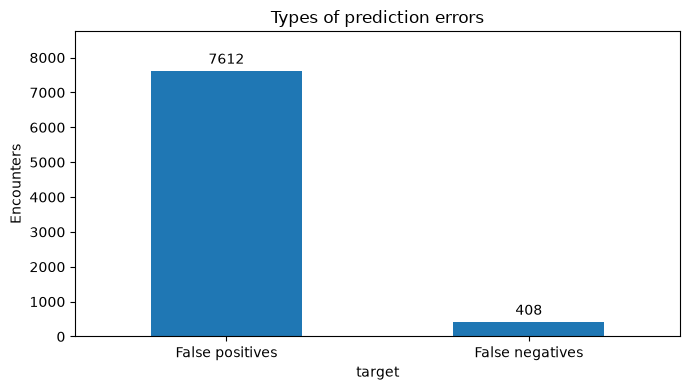

In [166]:
import pandas as pd
import matplotlib.pyplot as plt

audit = Xv.copy()

audit["result"] = "TN"
audit.loc[audit["target"].eq(0) & audit["y_pred"].eq(1), "result"] = "FP"
audit.loc[audit["target"].eq(1) & audit["y_pred"].eq(0), "result"] = "FN"
audit.loc[audit["target"].eq(1) & audit["y_pred"].eq(1), "result"] = "TP"

error_counts = (Errors["target"].map({0: "False positives", 1: "False negatives"}).value_counts().reindex(["False positives", "False negatives"], fill_value=0))

ax = error_counts.plot.bar(figsize=(7, 4), rot=0)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set_ylabel("Encounters")
ax.set_title("Types of prediction errors")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

number_inpatient        number_emergency        time_in_hospital  \
                   mean median             mean median             mean   
result                                                                    
FP                 0.95    1.0             0.26    0.0             5.08   
TP                 1.46    1.0             0.43    0.0             5.14   

              num_medications         
       median            mean median  
result                                
FP        4.0           17.43   17.0  
TP        4.0           18.06   17.0

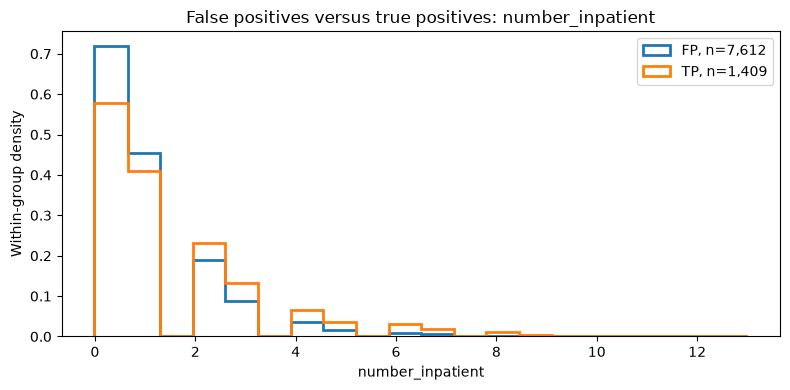

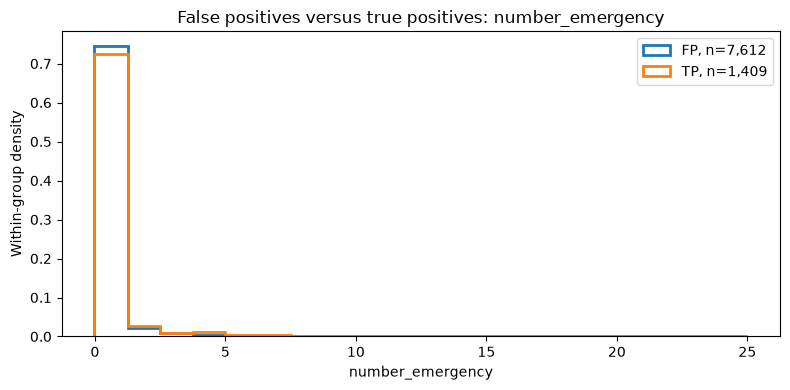

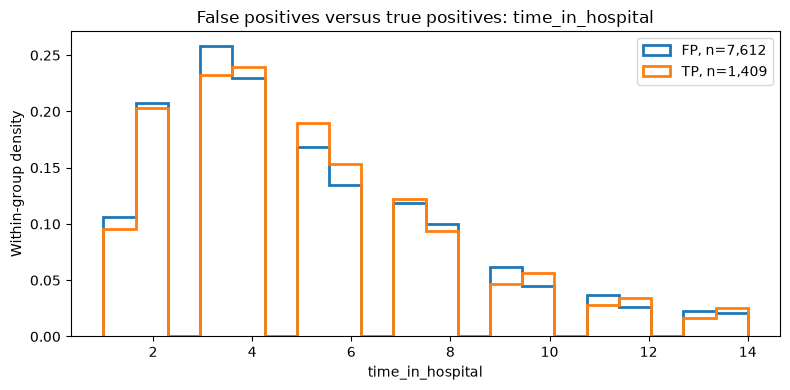

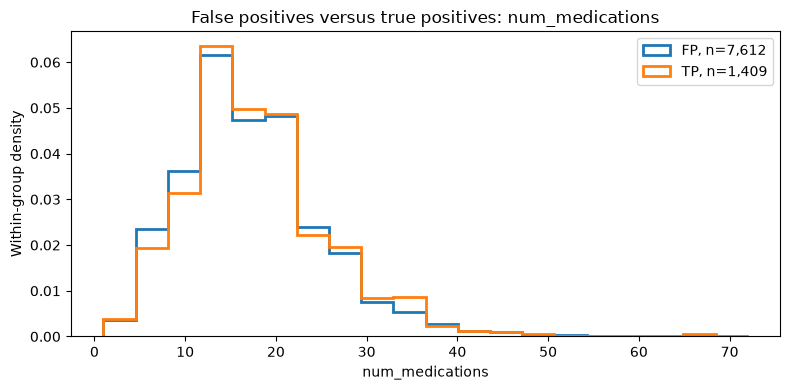

In [167]:
flagged = audit.loc[audit["y_pred"].eq(1)].copy()

columns = ["number_inpatient", "number_emergency", "time_in_hospital", "num_medications",]

display(flagged.groupby("result")[columns].agg(["mean", "median"]).round(2))

for column in columns:
    values = pd.to_numeric(flagged[column], errors="coerce")

    # use identical bin edges for both groups.
    edges = pd.cut(values.dropna(), bins=20, retbins=True)[1]

    plt.figure(figsize=(8, 4))

    for result in ["FP", "TP"]:
        group = values.loc[flagged["result"].eq(result)].dropna()
        plt.hist(group, bins=edges, density=True, histtype="step", linewidth=2, label=f"{result}, n={len(group):,}")

    plt.xlabel(column)
    plt.ylabel("Within-group density")
    plt.title(f"False positives versus true positives: {column}")
    plt.legend()
    plt.tight_layout()
    plt.show()

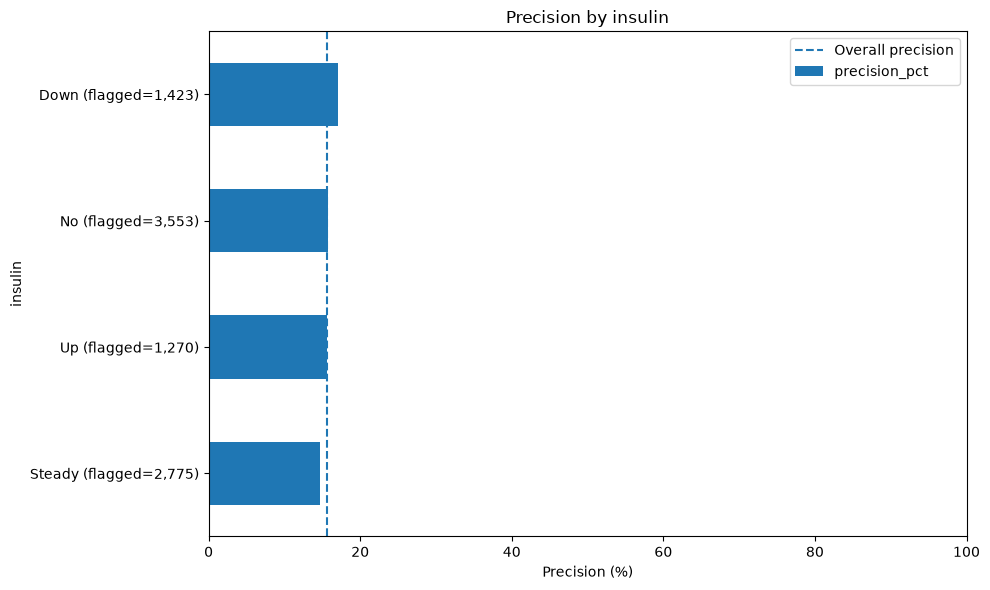

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
insulin,,,,,,,,
No,3728,2992,217,561,3553,15.79,44.52,27.89
Steady,2048,2368,119,407,2775,14.67,53.62,22.62
Down,565,1180,40,243,1423,17.08,67.62,14.13
Up,513,1072,32,198,1270,15.59,67.63,13.91


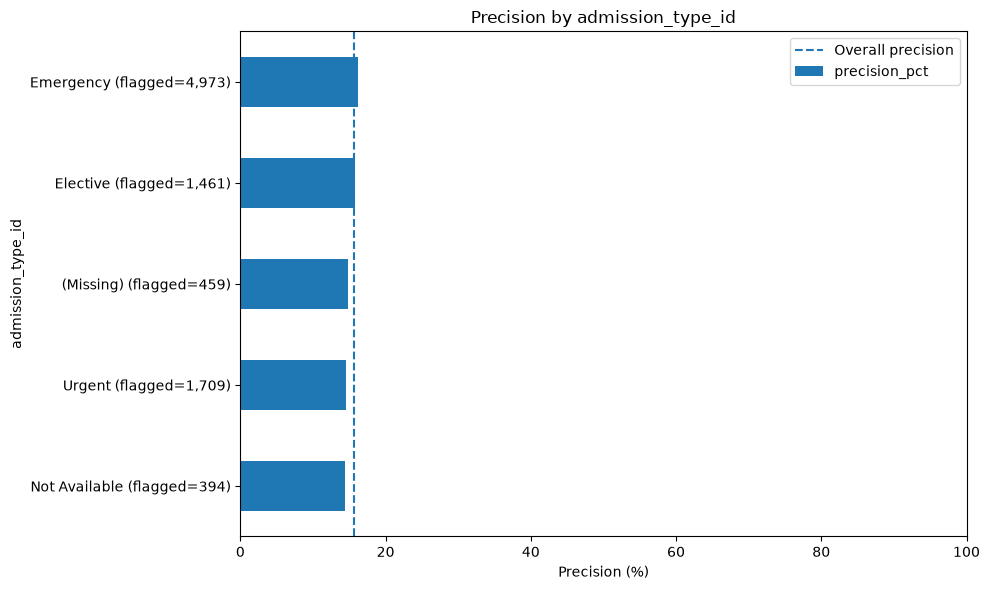

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
admission_type_id,,,,,,,,
Emergency,3458,4170,209,803,4973,16.15,54.67,20.65
Urgent,1140,1461,69,248,1709,14.51,56.17,21.77
Elective,1540,1231,82,230,1461,15.74,44.42,26.28
(Missing),346,391,23,68,459,14.81,53.05,25.27
Not Available,326,337,23,57,394,14.47,50.83,28.75
Not Mapped,38,20,2,3,23,13.04,34.48,40.00
Trauma Center,3,2,0,0,2,0.00,40.00,NaN
Newborn,3,0,0,0,0,NaN,0.00,NaN


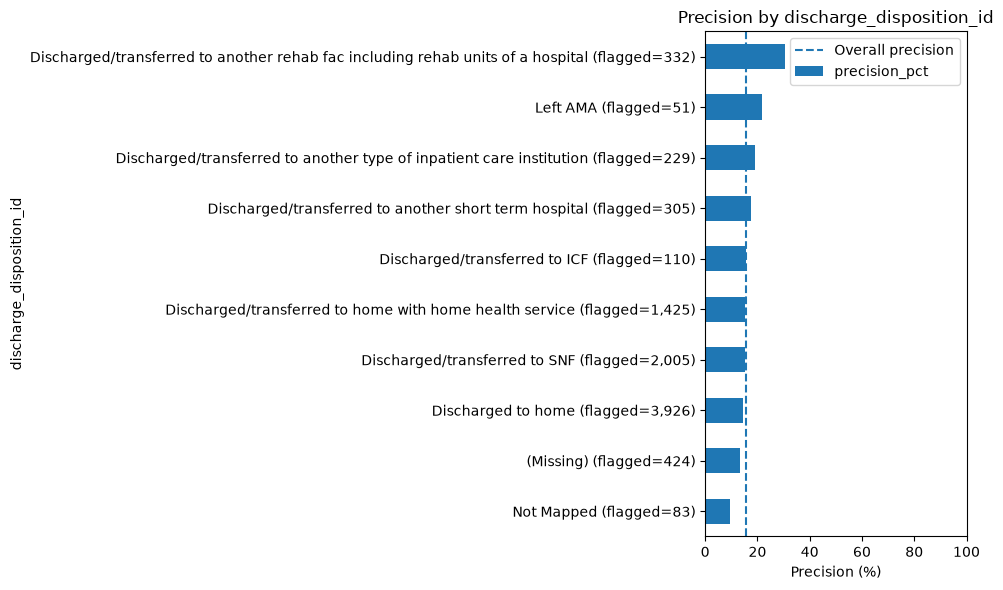

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
discharge_disposition_id,,,,,,,,
Discharged to home,5365,3356,333,570,3926,14.52,38.48,36.88
Discharged/transferred to SNF,196,1699,16,306,2005,15.26,89.66,4.97
Discharged/transferred to home with home health service,526,1207,29,218,1425,15.30,69.65,11.74
(Missing),156,367,14,57,424,13.44,70.17,19.72
Discharged/transferred to another short term hospital,56,251,0,54,305,17.70,81.76,0.00
Discharged/transferred to another rehab fac including rehab units of a hospital,1,231,0,101,332,30.42,99.57,0.00
Discharged/transferred to another type of inpatient care institution,0,185,0,44,229,19.21,100.00,0.00
Discharged/transferred to ICF,26,93,1,17,110,15.45,78.15,5.56
Not Mapped,63,75,2,8,83,9.64,54.35,20.00


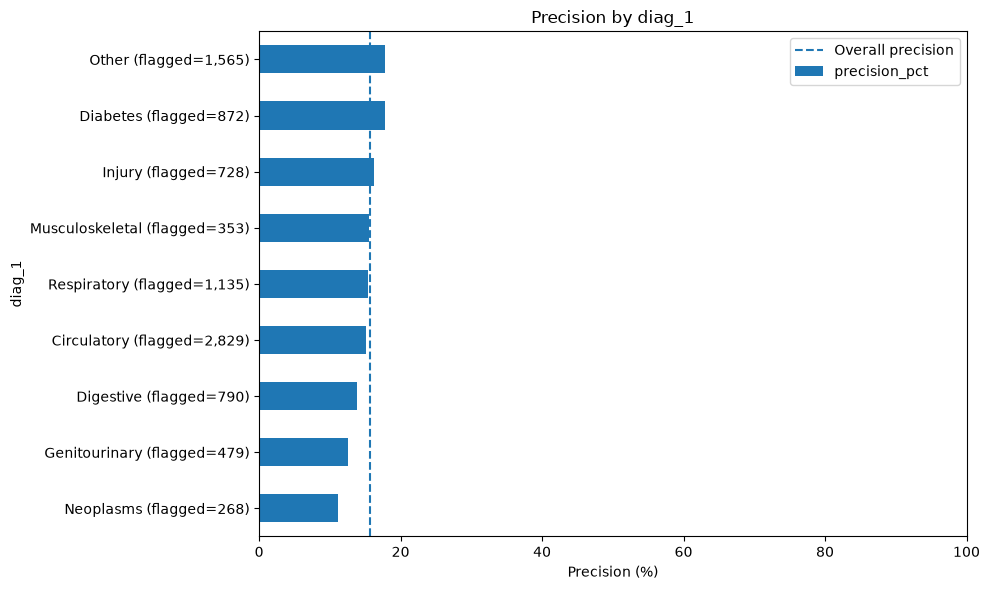

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
diag_1,,,,,,,,
Circulatory,1894,2401,139,428,2829,15.13,55.90,24.51
Other,1292,1286,77,279,1565,17.83,49.88,21.63
Respiratory,1175,960,70,175,1135,15.42,44.96,28.57
Diabetes,502,717,23,155,872,17.78,58.82,12.92
Digestive,630,681,38,109,790,13.80,51.95,25.85
Injury,348,610,20,118,728,16.21,63.67,14.49
Genitourinary,341,419,16,60,479,12.53,55.13,21.05
Musculoskeletal,421,298,15,55,353,15.58,41.45,21.43
Neoplasms,250,238,10,30,268,11.19,48.77,25.00


In [168]:
# We perform error analysis on based on grouping of insulin, admission types, discharge dispositions, and the actual diagnoses

group_tables = {}
overall_precision = 100 * flagged["target"].mean()

for column in ["insulin", "admission_type_id", "discharge_disposition_id","diag_1"]:
    groups = audit[column].astype("string").fillna("(Missing)")

    table = pd.crosstab(groups, audit["result"]).reindex(columns=["TN", "FP", "FN", "TP"], fill_value=0)

    table["flagged"] = table["TP"] + table["FP"]
    negatives = table["TN"] + table["FP"]
    positives = table["TP"] + table["FN"]

    table["precision_pct"] = 100 * table["TP"] / table["flagged"].where(table["flagged"] > 0)
    

    table["FPR_pct"] = 100 * table["FP"] / negatives.where(negatives > 0)

    table["FNR_pct"] = 100 * table["FN"] / positives.where(positives > 0)

    group_tables[column] = table

    # Show common groups with at least 50 positive predictions.
    shown = table.loc[table["flagged"] >= 50].nlargest(12, "flagged").sort_values("precision_pct")

    ax = shown["precision_pct"].plot.barh(figsize=(10, 6))

    ax.set_yticks(range(len(shown)),[f"{group} (flagged={int(n):,})" for group, n in shown["flagged"].items()])

    ax.axvline(overall_precision, linestyle="--", label="Overall precision")

    ax.set_xlim(0, 100)
    ax.set_xlabel("Precision (%)")
    ax.set_title(f"Precision by {column}")
    ax.legend()
    plt.tight_layout()
    plt.show()

    # Rank by the actual number of false positives.
    display(table.sort_values("FP", ascending=False).head(12).round(2))

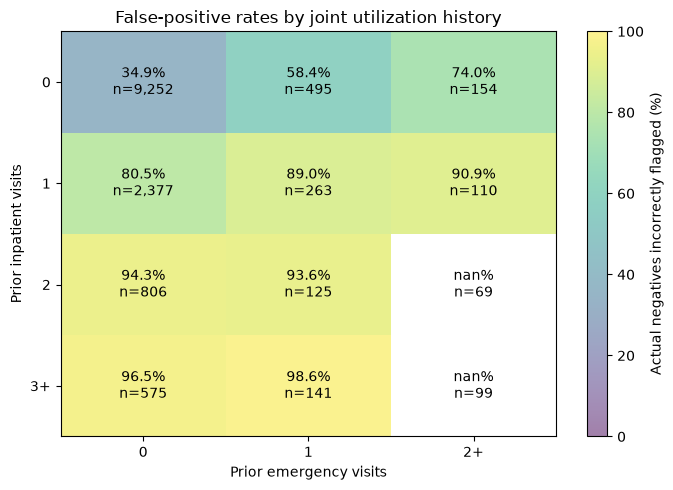

actual_negatives  false_positives    FPR
inpatient_band emergency_band                                          
0              0                           9252             3228  0.349
               1                            495              289  0.584
               2+                           154              114  0.740
1              0                           2377             1913  0.805
               1                            263              234  0.890
               2+                           110              100  0.909
2              0                            806              760  0.943
               1                            125              117  0.936
               2+                            69               66  0.957
3+             0                            575              555  0.965
               1                            141              139  0.986
               2+                            99               97  0.980

In [169]:
audit["inpatient_band"] = pd.cut(pd.to_numeric(audit["number_inpatient"], errors="coerce"), bins=[-float("inf"), 0, 1, 2, float("inf")], labels=["0", "1", "2", "3+"])

audit["emergency_band"] = pd.cut(pd.to_numeric(audit["number_emergency"], errors="coerce"), bins=[-float("inf"), 0, 1, float("inf")], labels=["0", "1", "2+"])

negative = audit.loc[audit["target"].eq(0)]

joint = negative.groupby(["inpatient_band", "emergency_band"], observed=True)["y_pred"].agg(actual_negatives="size", false_positives="sum", FPR="mean")

counts = joint["actual_negatives"].unstack().reindex(index=["0", "1", "2", "3+"],columns=["0", "1", "2+"]).fillna(0)

rates = 100 * joint["FPR"].unstack().reindex_like(counts)
shown = rates.where(counts >= 100)

plt.figure(figsize=(7, 5))
plt.imshow(shown.to_numpy(dtype=float), aspect="auto",vmin=0, vmax=100, alpha=0.5)

plt.xticks(range(len(shown.columns)), shown.columns)
plt.yticks(range(len(shown.index)), shown.index)

for i in range(len(shown.index)):
    for j in range(len(shown.columns)):
        plt.text(j, i, f"{shown.iloc[i, j]:.1f}%\nn={int(counts.iloc[i, j]):,}", ha="center", va="center")

plt.xlabel("Prior emergency visits")
plt.ylabel("Prior inpatient visits")
plt.title("False-positive rates by joint utilization history")
plt.colorbar(label="Actual negatives incorrectly flagged (%)")
plt.tight_layout()
plt.show()

display(joint.round(3))

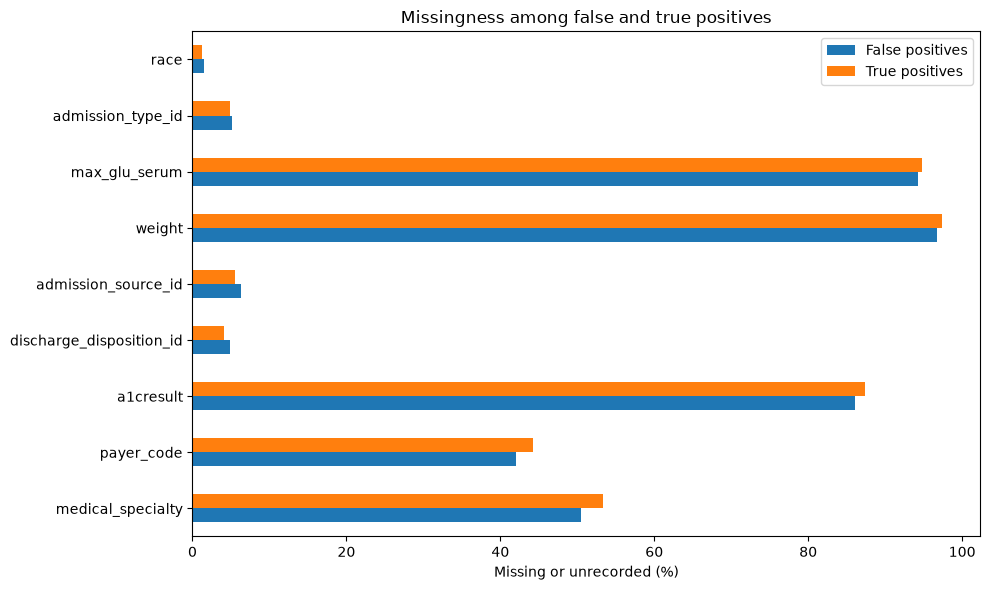

,False positives,True positives,difference_percentage_points
medical_specialty,50.50,53.30,-2.80
payer_code,42.07,44.29,-2.22
a1cresult,86.14,87.44,-1.30
discharge_disposition_id,4.82,4.05,0.78
admission_source_id,6.27,5.54,0.73
weight,96.79,97.44,-0.65
max_glu_serum,94.32,94.75,-0.42
admission_type_id,5.14,4.83,0.31
race,1.55,1.28,0.27


In [170]:
columns = [column for column in flagged.columns if column not in ["target", "y_pred", "result", "patient_nbr", "encounter_id"]]

missing = flagged[columns].isna() | flagged[columns].astype("string").isin(["?", "", "missing"])

missing_rates = 100 * pd.DataFrame({"False positives": missing.loc[flagged["result"].eq("FP")].mean(),
                                    "True positives": missing.loc[flagged["result"].eq("TP")].mean()})

missing_rates = missing_rates.loc[missing_rates.gt(0).any(axis=1)]

difference = missing_rates["False positives"] - missing_rates["True positives"]

order = difference.abs().nlargest(12).index

if len(order):
    missing_rates.loc[order].plot.barh(figsize=(10, 6))
    plt.xlabel("Missing or unrecorded (%)")
    plt.ylabel("")
    plt.title("Missingness among false and true positives")
    plt.tight_layout()
    plt.show()

    display(missing_rates.assign(difference_percentage_points=difference).loc[order].round(2))